<a href="https://colab.research.google.com/github/yvonneliuYL/IE7615-Group2-Discriminative-Project/blob/main/Week2_MultiObject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os, zipfile

DRIVE_DIR = "/content/drive/MyDrive/IE7615_data/Project1"
DATA_DIR = "/content/IE7615 Deep Learning for AI"

if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(f"{DRIVE_DIR}/database.zip") as z:
        z.extractall("/content")

folders = sorted(d for d in os.listdir(DATA_DIR) if d.startswith("images_OBJ"))
print("Number of object folders:", len(folders))
print(folders[:3], "...", folders[-3:])

Number of object folders: 73
['images_OBJ001', 'images_OBJ002', 'images_OBJ003'] ... ['images_OBJ071', 'images_OBJ072', 'images_OBJ073']


In [5]:
import re
import numpy as np
from sklearn.model_selection import train_test_split

IMG_RE = re.compile(r"\.jpe?g$", re.I)
BG_RE = re.compile(r"_bg_", re.I)
SEED = 42

class_names = [d.replace("images_", "") for d in folders]

paths, labels, bg_paths = [], [], []
for i, d in enumerate(folders):
    for f in sorted(os.listdir(os.path.join(DATA_DIR, d))):
        if not IMG_RE.search(f):
            continue
        p = os.path.join(DATA_DIR, d, f)
        if BG_RE.search(f):
            bg_paths.append(p)
        else:
            paths.append(p)
            labels.append(i)

paths, labels = np.array(paths), np.array(labels)

# same split as Milestone 1
p_train, p_tmp, y_train, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

# split backgrounds too, so test backgrounds are not reused in training
bg_train, bg_tmp = train_test_split(bg_paths, test_size=0.30, random_state=SEED)
bg_val, bg_test = train_test_split(bg_tmp, test_size=0.50, random_state=SEED)

print("Classes:", len(class_names))
print("Object images:", len(paths), "| train", len(p_train), "| val", len(p_val), "| test", len(p_test))
print("Background images:", len(bg_paths), "| train", len(bg_train), "| val", len(bg_val), "| test", len(bg_test))

Classes: 73
Object images: 6964 | train 4874 | val 1045 | test 1045
Background images: 379 | train 265 | val 57 | test 57


In [6]:
import random
from PIL import Image, ImageOps

IMG_OUT = 640
YOLO_DIR = "/content/yolo_data"

def place_boxes(n, rng):
    # pick n square boxes that do not overlap
    boxes, tries = [], 0
    while len(boxes) < n and tries < 300:
        tries += 1
        s = rng.randint(110, 220)
        x = rng.randint(0, IMG_OUT - s)
        y = rng.randint(0, IMG_OUT - s)
        if all(x + s <= bx or bx + bs <= x or y + s <= by or by + bs <= y for bx, by, bs in boxes):
            boxes.append((x, y, s))
    return boxes

def make_split(name, obj_paths, obj_labels, bgs, n_images, seed):
    rng = random.Random(seed)
    img_dir = f"{YOLO_DIR}/images/{name}"
    lbl_dir = f"{YOLO_DIR}/labels/{name}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    for k in range(n_images):
        canvas = Image.open(rng.choice(bgs)).convert("RGB").resize((IMG_OUT, IMG_OUT))
        lines = []
        for (x, y, s) in place_boxes(rng.randint(2, 5), rng):
            j = rng.randrange(len(obj_paths))
            obj = Image.open(obj_paths[j]).convert("RGB").resize((s, s))
            if rng.random() < 0.5:
                obj = ImageOps.mirror(obj)   # augmentation: horizontal flip
            canvas.paste(obj, (x, y))
            cx, cy, w = (x + s / 2) / IMG_OUT, (y + s / 2) / IMG_OUT, s / IMG_OUT
            lines.append(f"{int(obj_labels[j])} {cx:.6f} {cy:.6f} {w:.6f} {w:.6f}")
        canvas.save(f"{img_dir}/{name}_{k:05d}.jpg", quality=92)
        with open(f"{lbl_dir}/{name}_{k:05d}.txt", "w") as f:
            f.write("\n".join(lines) + "\n")
    print(f"{name}: {n_images} images created")

make_split("train", p_train, y_train, bg_train, 1500, seed=1)
make_split("val",   p_val,   y_val,   bg_val,   300,  seed=2)
make_split("test",  p_test,  y_test,  bg_test,  300,  seed=3)

# settings file that YOLOv8 reads
with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n")
    for i, n in enumerate(class_names):
        f.write(f"  {i}: {n}\n")

print(open(f"{YOLO_DIR}/labels/train/train_00000.txt").read())

train: 1500 images created
val: 300 images created
test: 300 images created
4 0.204687 0.506250 0.221875 0.221875
53 0.521094 0.538281 0.323437 0.323437



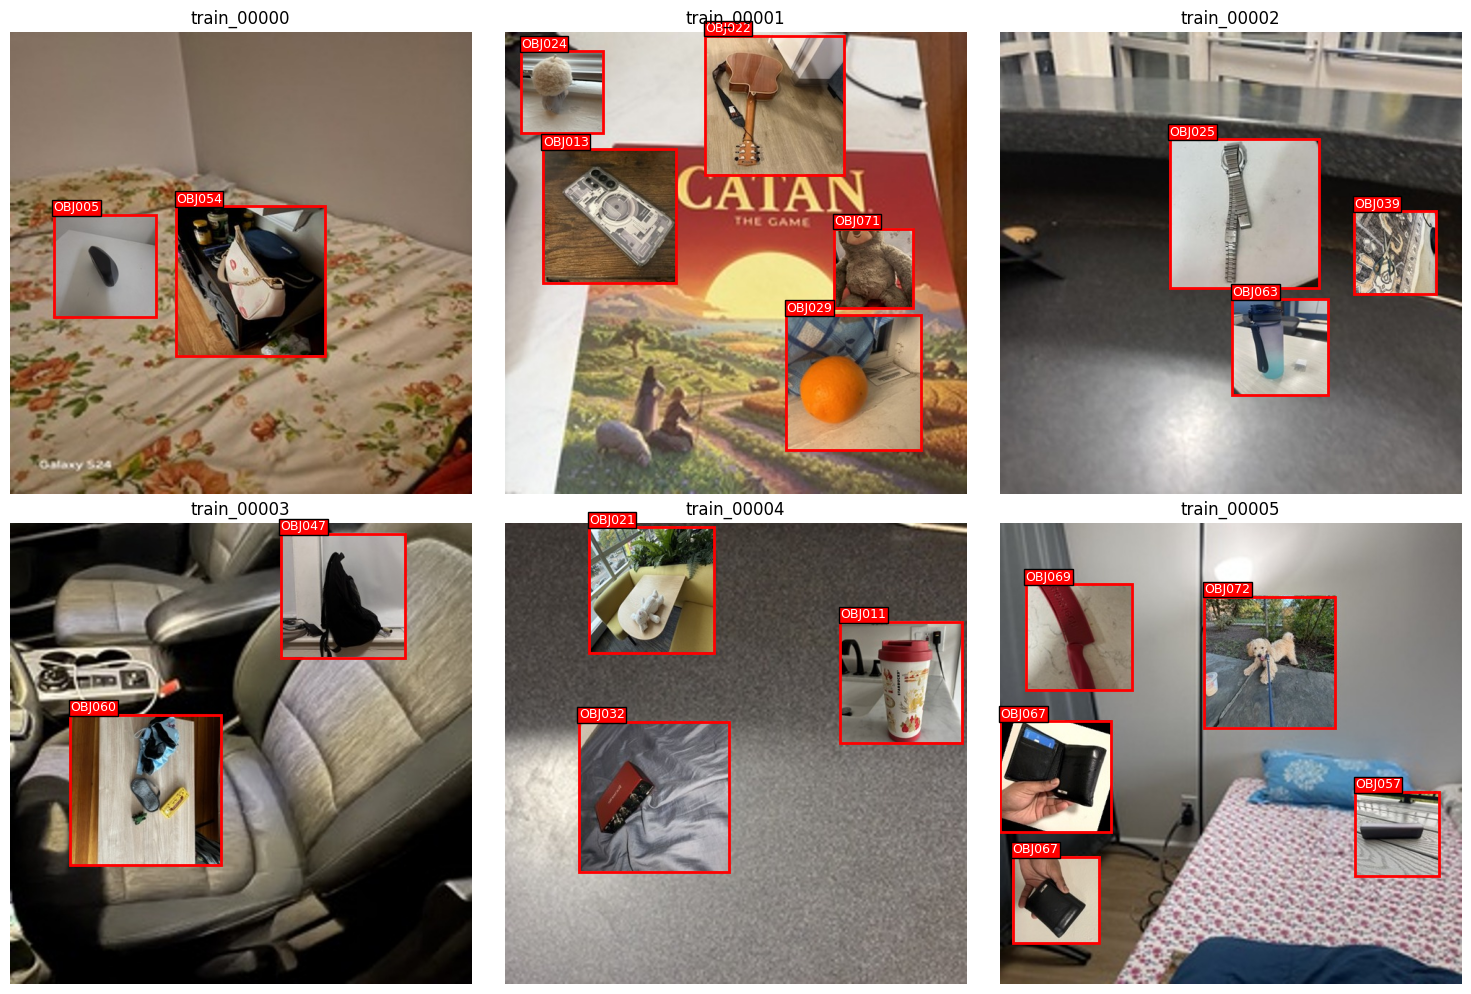

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show_with_boxes(split, idx, ax):
    img = Image.open(f"{YOLO_DIR}/images/{split}/{split}_{idx:05d}.jpg")
    ax.imshow(img)
    for line in open(f"{YOLO_DIR}/labels/{split}/{split}_{idx:05d}.txt").read().split("\n"):
        if not line.strip():
            continue
        c, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * IMG_OUT, float(cy) * IMG_OUT, float(w) * IMG_OUT, float(h) * IMG_OUT
        ax.add_patch(patches.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, edgecolor="red", linewidth=2))
        ax.text(cx - w / 2, cy - h / 2 - 5, class_names[int(c)], color="white", fontsize=9,
                bbox=dict(facecolor="red", pad=1))
    ax.axis("off")
    ax.set_title(f"{split}_{idx:05d}")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, idx in zip(axes.flat, [0, 1, 2, 3, 4, 5]):
    show_with_boxes("train", idx, ax)
plt.tight_layout()
plt.show()

In [8]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.4 MB/s eta 0:00:00


In [9]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [10]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")   # small YOLOv8 model, pretrained on COCO

results = model.train(
    data=f"{YOLO_DIR}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,          # stop early if validation results stop improving for 15 epochs
    seed=SEED,
    project=f"{DRIVE_DIR}/week2_results",
    name="yolov8s",
    exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

In [11]:
best_model = YOLO(f"{DRIVE_DIR}/week2_results/yolov8s/weights/best.pt")

test_metrics = best_model.val(
    data=f"{YOLO_DIR}/data.yaml",
    split="test",
    project=f"{DRIVE_DIR}/week2_results",
    name="test_eval",
    exist_ok=True,
)

print("\nTEST RESULTS")
print("Precision:", round(test_metrics.box.mp, 3))
print("Recall:", round(test_metrics.box.mr, 3))
print("mAP50:", round(test_metrics.box.map50, 3))
print("mAP50-95:", round(test_metrics.box.map, 3))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 21.7±16.0 MB/s, size: 92.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/yolo_data/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 224.7it/s 1.3s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.2it/s 8.6s
                   all        300       1050      0.944      0.924      0.962      0.962
                OBJ001          7          7      0.959          1      0.995      0.995
                OBJ002         17         18          1      0.981      0.995      0.995
                

Image: test_00000.jpg
Objects found: 3

Object ID  Confidence     x1    y1    x2    y2
OBJ070     1.00          282   119   425   262
OBJ046     0.99           13   480   131   598
OBJ029     0.99          468   309   625   466


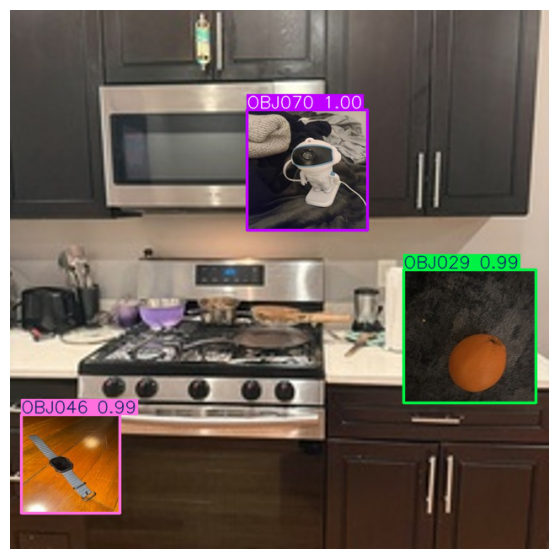

In [12]:
def detect_objects(image_path, conf=0.5):
    result = best_model.predict(image_path, conf=conf, verbose=False)[0]
    print(f"Image: {os.path.basename(image_path)}")
    print(f"Objects found: {len(result.boxes)}\n")
    print(f"{'Object ID':<10} {'Confidence':<11} {'x1':>5} {'y1':>5} {'x2':>5} {'y2':>5}")
    for box in result.boxes:
        cls_id = int(box.cls[0])
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        print(f"{class_names[cls_id]:<10} {float(box.conf[0]):<11.2f} {x1:5.0f} {y1:5.0f} {x2:5.0f} {y2:5.0f}")
    plt.figure(figsize=(7, 7))
    plt.imshow(result.plot()[:, :, ::-1])   # draw boxes; convert BGR to RGB
    plt.axis("off")
    plt.show()

detect_objects(f"{YOLO_DIR}/images/test/test_00000.jpg")

In [13]:
def true_labels(split, idx):
    print(f"TRUE objects in {split}_{idx:05d}:")
    for line in open(f"{YOLO_DIR}/labels/{split}/{split}_{idx:05d}.txt").read().split("\n"):
        if not line.strip():
            continue
        c, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * IMG_OUT, float(cy) * IMG_OUT, float(w) * IMG_OUT, float(h) * IMG_OUT
        print(f"{class_names[int(c)]:<10} {cx - w/2:5.0f} {cy - h/2:5.0f} {cx + w/2:5.0f} {cy + h/2:5.0f}")

true_labels("test", 0)

TRUE objects in test_00000:
OBJ029       468   309   625   466
OBJ046        13   480   131   598
OBJ070       282   119   425   262
